# Smart Audio Denoising System

## Project Overview

This project focuses on reducing noise in audio signals using Digital Signal Processing (DSP) techniques.

## Objectives

* Load and analyze an audio signal.
* Add artificial Gaussian noise to the original audio.
* Apply different digital filters.
* Compare filtering performance using evaluation metrics.
* Visualize the original, noisy, and denoised audio signals.

## Filters

1. Moving Average Filter
2. Butterworth Low-Pass Filter
3. Median Filter

## Evaluation Metrics

* Mean Squared Error (MSE)
* Root Mean Squared Error (RMSE)
* Signal-to-Noise Ratio (SNR)


In [1]:
from pathlib import Path

audio_path = Path("original_audio.wav")

print("File exists:", audio_path.exists())

if audio_path.exists():
    print("File size:", audio_path.stat().st_size, "bytes")

    with open(audio_path, "rb") as f:
        print("File header:", f.read(100))

File exists: True
File size: 441044 bytes
File header: b'RIFF\xcc\xba\x06\x00WAVEfmt \x10\x00\x00\x00\x01\x00\x01\x00D\xac\x00\x00\x88X\x01\x00\x02\x00\x10\x00data\xa8\xba\x06\x00|\xfe\xc5\xf2\xe6\xed\x94\xf0~\xf56\xf90\xfb\r\xfd\x03\x02\xb8\n\x17\x138\x17I\x16\x8f\x0f\xfc\x02\xe5\xf4\xde\xec\xc4\xee\xf6\xf6\t\xff\xdb\x02\x89\x03\x85\x06\xce\x0c\xe2\x10;\x109\x0ch\x04'


In [2]:
import urllib.request
from pathlib import Path

audio_url = "https://raw.githubusercontent.com/karoldvl/ESC-50/master/audio/1-100038-A-14.wav"
audio_path = Path("original_audio.wav")

request = urllib.request.Request(
    audio_url,
    headers={"User-Agent": "Mozilla/5.0"}
)

try:
    with urllib.request.urlopen(request, timeout=30) as response:
        audio_bytes = response.read()

    if not audio_bytes.startswith(b"RIFF"):
        raise ValueError("The downloaded file is not a valid WAV file.")

    audio_path.write_bytes(audio_bytes)

    print("Audio downloaded successfully!")
    print("File size:", len(audio_bytes), "bytes")
    print("Saved to:", audio_path.resolve())

except Exception as error:
    print("Download failed:", error)

Audio downloaded successfully!
File size: 441044 bytes
Saved to: C:\Users\hp\OneDrive - Faculty Of Engineering (Kafr Elsheikh University)\Desktop\Smart Audio Denoising System\original_audio.wav


In [3]:
import soundfile as sf
import numpy as np
from IPython.display import Audio, display

audio, sr = sf.read(audio_path)


if audio.ndim == 2:
    audio = audio.mean(axis=1)

audio = audio.astype(np.float64)


peak = np.max(np.abs(audio))
if peak > 0:
    audio = audio / peak

duration = len(audio) / sr

print("Sampling Rate:", sr, "Hz")
print("Duration:", round(duration, 2), "seconds")
print("Number of Samples:", len(audio))

display(Audio(audio, rate=sr))

Sampling Rate: 44100 Hz
Duration: 5.0 seconds
Number of Samples: 220500


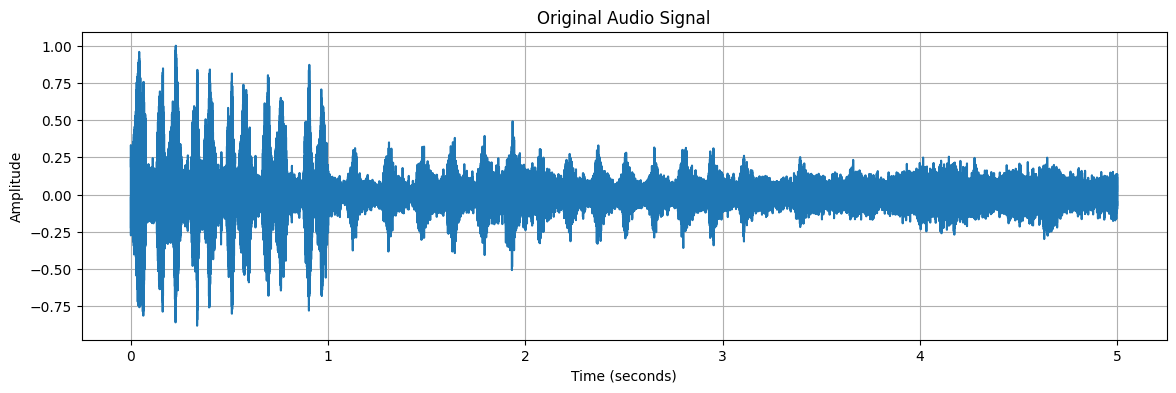

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Create time axis
time = np.arange(len(audio)) / sr

# Plot original audio signal
plt.figure(figsize=(14, 4))
plt.plot(time, audio)
plt.title("Original Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

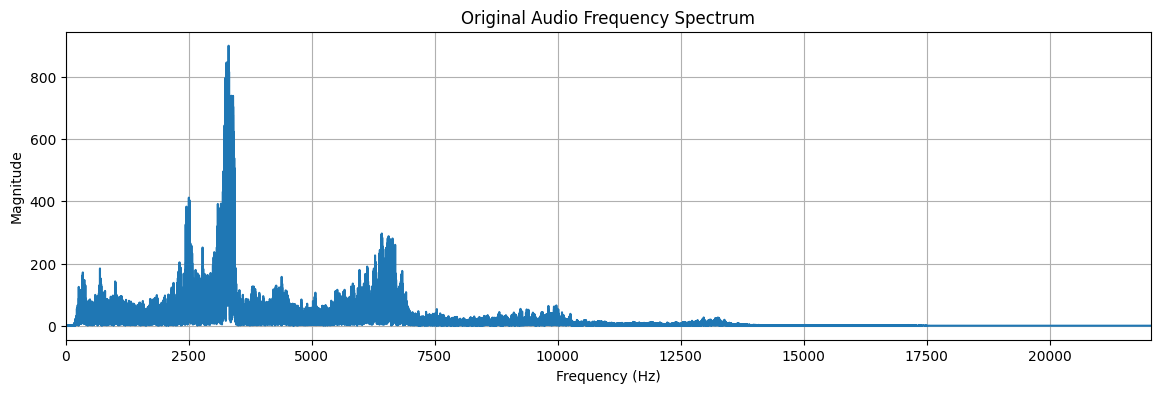

In [5]:
# Calculate frequency spectrum
n = len(audio)

frequencies = np.fft.rfftfreq(n, d=1/sr)
spectrum = np.abs(np.fft.rfft(audio))

plt.figure(figsize=(14, 4))
plt.plot(frequencies, spectrum)
plt.title("Original Audio Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, sr / 2)
plt.grid(True)
plt.show()

In [6]:
# Set random seed for reproducible results
np.random.seed(42)

# Generate random noise
noise_level = 0.05
noise = np.random.normal(
    loc=0,
    scale=noise_level,
    size=len(audio)
)

# Add noise to original audio
noisy_audio = audio + noise

# Prevent clipping
noisy_audio = np.clip(noisy_audio, -1, 1)

print("Noise added successfully!")
print("Original audio samples:", len(audio))
print("Noisy audio samples:", len(noisy_audio))

Noise added successfully!
Original audio samples: 220500
Noisy audio samples: 220500


In [7]:
from IPython.display import Audio, display

print("Original Audio:")
display(Audio(audio, rate=sr))

print("Noisy Audio:")
display(Audio(noisy_audio, rate=sr))

Original Audio:


Noisy Audio:


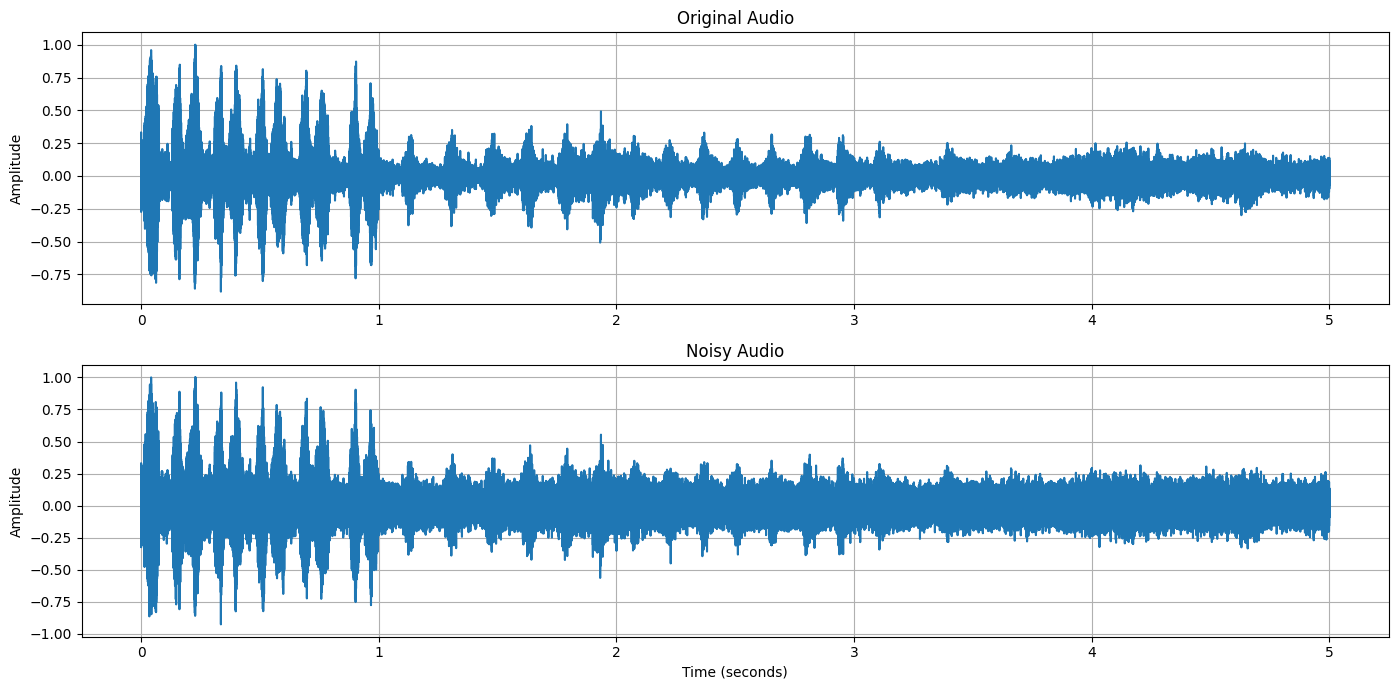

In [8]:
plt.figure(figsize=(14, 7))

plt.subplot(2, 1, 1)
plt.plot(time, audio)
plt.title("Original Audio")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, noisy_audio)
plt.title("Noisy Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

In [9]:
# Calculate Signal-to-Noise Ratio
signal_power = np.mean(audio ** 2)
noise_power = np.mean((noisy_audio - audio) ** 2)

snr_db = 10 * np.log10(signal_power / noise_power)

print(f"Signal Power: {signal_power:.6f}")
print(f"Noise Power: {noise_power:.6f}")
print(f"SNR before filtering: {snr_db:.2f} dB")

Signal Power: 0.012680
Noise Power: 0.002498
SNR before filtering: 7.05 dB


In [10]:
from scipy.signal import butter, sosfiltfilt, medfilt
import numpy as np
import matplotlib.pyplot as plt

print("Filtering libraries are ready!")

Filtering libraries are ready!


In [11]:
def moving_average_filter(signal, window_size=5):
    """
    Apply a moving average filter to a signal.
    """
    if window_size < 1:
        raise ValueError("window_size must be positive")

    kernel = np.ones(window_size) / window_size

    filtered_signal = np.convolve(
        signal,
        kernel,
        mode="same"
    )

    return filtered_signal


moving_avg_audio = moving_average_filter(
    noisy_audio,
    window_size=5
)

print("Moving Average Filter applied successfully!")

Moving Average Filter applied successfully!


In [12]:
def low_pass_filter(signal, sampling_rate, cutoff=4000, order=4):
    """
    Apply a Butterworth low-pass filter.
    """
    nyquist_frequency = sampling_rate / 2

    if not 0 < cutoff < nyquist_frequency:
        raise ValueError(
            f"cutoff must be between 0 and {nyquist_frequency} Hz"
        )

    sos = butter(
        order,
        cutoff,
        btype="lowpass",
        fs=sampling_rate,
        output="sos"
    )

    filtered_signal = sosfiltfilt(sos, signal)

    return filtered_signal


low_pass_audio = low_pass_filter(
    noisy_audio,
    sampling_rate=sr,
    cutoff=4000
)

print("Low-Pass Filter applied successfully!")

Low-Pass Filter applied successfully!


In [13]:
def median_filter(signal, kernel_size=5):
    """
    Apply a median filter to a signal.
    """
    if kernel_size < 3 or kernel_size % 2 == 0:
        raise ValueError("kernel_size must be an odd number >= 3")

    return medfilt(
        signal,
        kernel_size=kernel_size
    )


median_audio = median_filter(
    noisy_audio,
    kernel_size=5
)

print("Median Filter applied successfully!")

Median Filter applied successfully!


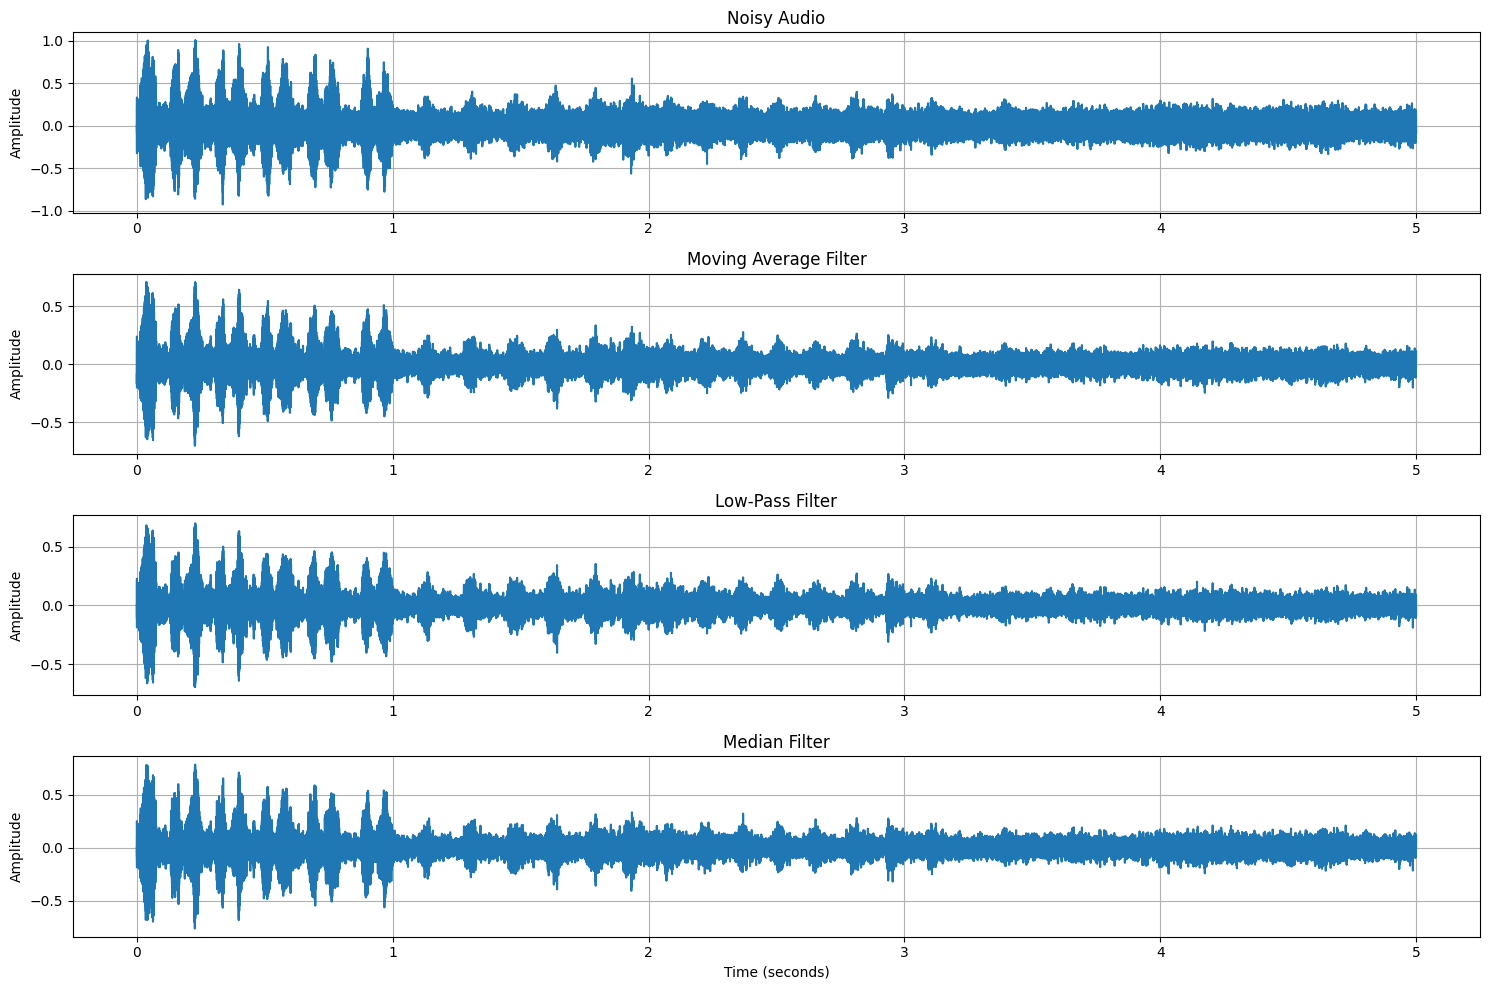

In [14]:
plt.figure(figsize=(15, 10))

plt.subplot(4, 1, 1)
plt.plot(time, noisy_audio)
plt.title("Noisy Audio")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(time, moving_avg_audio)
plt.title("Moving Average Filter")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(time, low_pass_audio)
plt.title("Low-Pass Filter")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(time, median_audio)
plt.title("Median Filter")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
from IPython.display import Audio, display

print("1. Original Audio")
display(Audio(audio, rate=sr))

print("2.Noisy Audio")
display(Audio(noisy_audio, rate=sr))

print("3. Moving Average Filter")
display(Audio(moving_avg_audio, rate=sr))

print("4. Low-Pass Filter")
display(Audio(low_pass_audio, rate=sr))

print("5. Median Filter")
display(Audio(median_audio, rate=sr))

1. Original Audio


2.Noisy Audio


3. Moving Average Filter


4. Low-Pass Filter


5. Median Filter


In [16]:
def calculate_metrics(original, processed):
    """
    Calculate MSE, RMSE, and output SNR.
    """
    error = original - processed

    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)

    signal_power = np.mean(original ** 2)
    error_power = np.mean(error ** 2)

    if error_power == 0:
        snr = float("inf")
    elif signal_power == 0:
        snr = float("-inf")
    else:
        snr = 10 * np.log10(signal_power / error_power)

    return mse, rmse, snr


print("Metrics functions are ready!")

Metrics functions are ready!


In [17]:
results = {
    "Noisy Audio": noisy_audio,
    "Moving Average": moving_avg_audio,
    "Low-Pass": low_pass_audio,
    "Median": median_audio
}

metrics_results = {}

for name, processed_audio in results.items():
    mse, rmse, snr = calculate_metrics(
        audio,
        processed_audio
    )

    metrics_results[name] = {
        "MSE": mse,
        "RMSE": rmse,
        "SNR (dB)": snr
    }

    print(f"\n{name}")
    print(f"MSE: {mse:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"SNR: {snr:.2f} dB")


Noisy Audio
MSE: 0.00249825
RMSE: 0.04998249
SNR: 7.05 dB

Moving Average
MSE: 0.00194215
RMSE: 0.04406986
SNR: 8.15 dB

Low-Pass
MSE: 0.00287341
RMSE: 0.05360416
SNR: 6.45 dB



Median
MSE: 0.00170670
RMSE: 0.04131218
SNR: 8.71 dB


In [18]:
import pandas as pd

metrics_df = pd.DataFrame(metrics_results).T

metrics_df = metrics_df.sort_values(
    by="SNR (dB)",
    ascending=False
)

display(metrics_df.round(6))

,MSE,RMSE,SNR (dB)
Median,0.001707,0.041312,8.709698
Moving Average,0.001942,0.044070,8.148427
Noisy Audio,0.002498,0.049982,7.054903
Low-Pass,0.002873,0.053604,6.447292


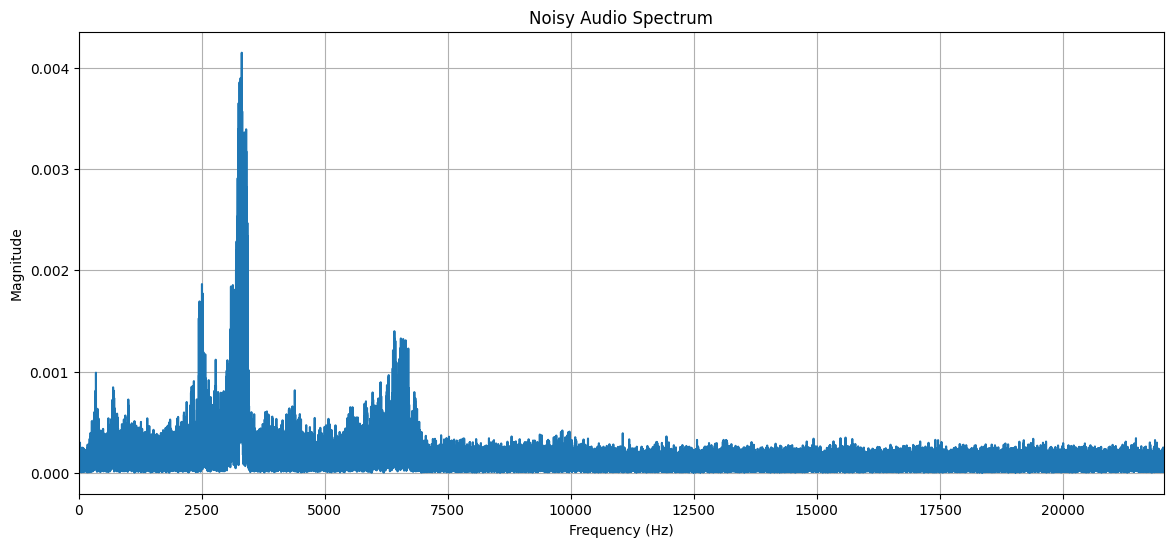

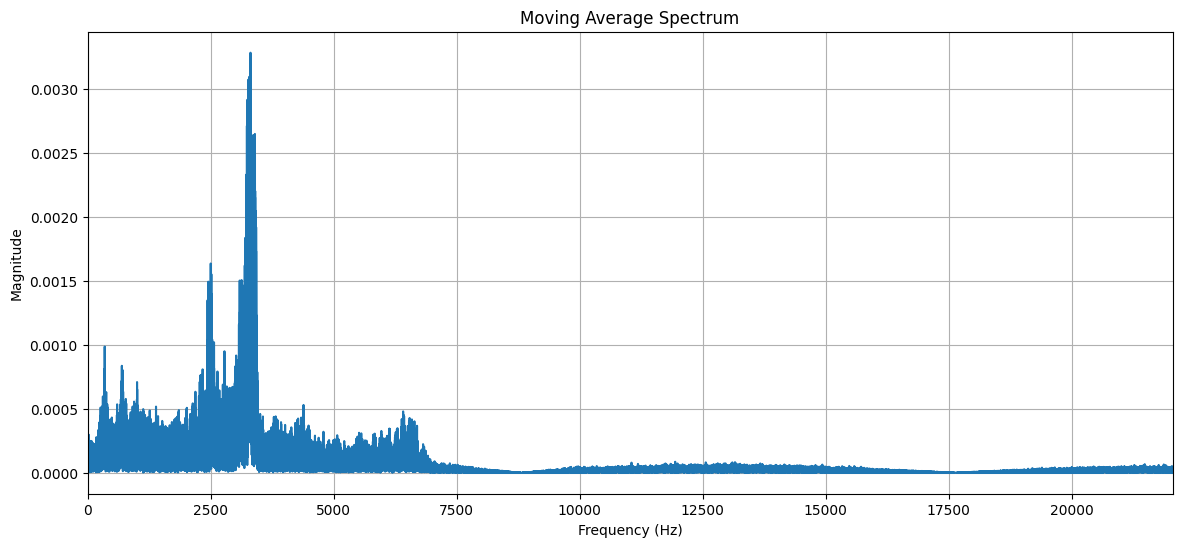

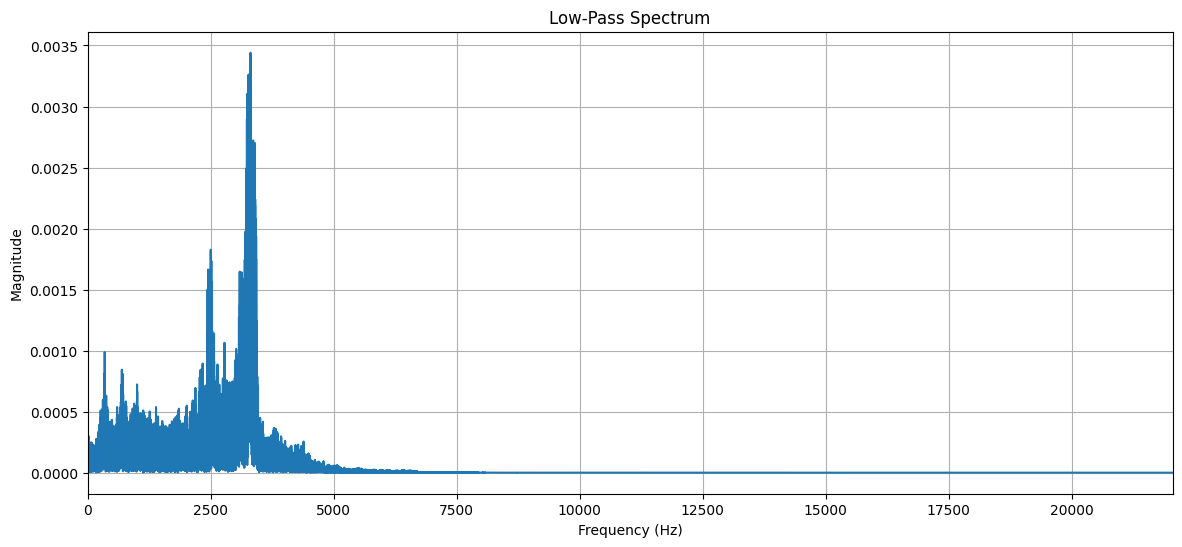

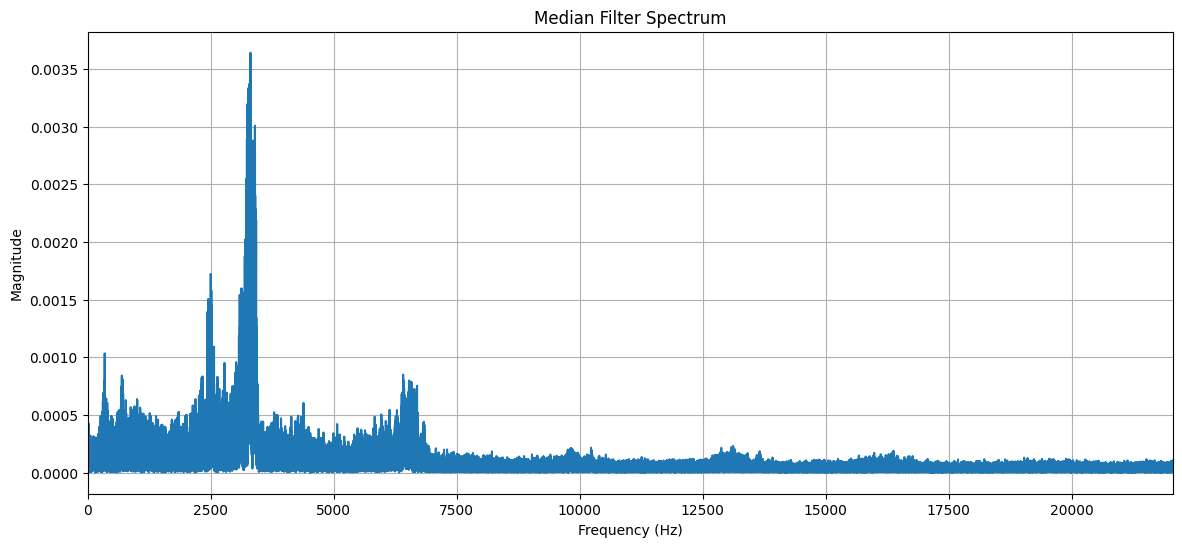

In [19]:
def plot_frequency_spectrum(signal, sampling_rate, title):
    n = len(signal)

    frequencies = np.fft.rfftfreq(
        n,
        d=1 / sampling_rate
    )

    spectrum = np.abs(np.fft.rfft(signal)) / n

    plt.plot(frequencies, spectrum)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.xlim(0, sampling_rate / 2)
    plt.grid(True)


plt.figure(figsize=(14, 6))

plot_frequency_spectrum(
    noisy_audio,
    sr,
    "Noisy Audio Spectrum"
)

plt.show()

plt.figure(figsize=(14, 6))

plot_frequency_spectrum(
    moving_avg_audio,
    sr,
    "Moving Average Spectrum"
)

plt.show()

plt.figure(figsize=(14, 6))

plot_frequency_spectrum(
    low_pass_audio,
    sr,
    "Low-Pass Spectrum"
)

plt.show()

plt.figure(figsize=(14, 6))

plot_frequency_spectrum(
    median_audio,
    sr,
    "Median Filter Spectrum"
)

plt.show()

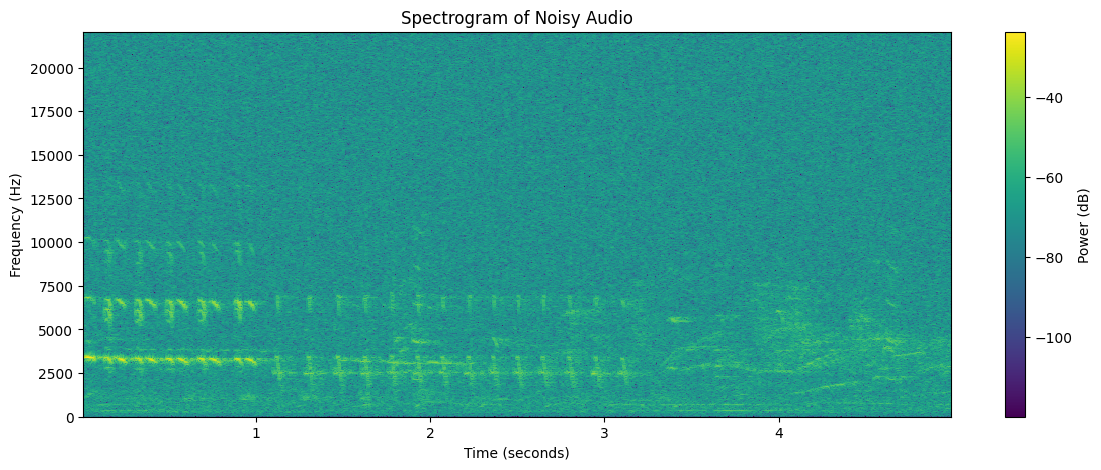

In [20]:
from scipy.signal import spectrogram

frequencies, times, power = spectrogram(
    noisy_audio,
    fs=sr,
    nperseg=1024,
    noverlap=768
)

plt.figure(figsize=(14, 5))

plt.pcolormesh(
    times,
    frequencies,
    10 * np.log10(power + 1e-12),
    shading="auto"
)

plt.title("Spectrogram of Noisy Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Power (dB)")
plt.ylim(0, sr / 2)

plt.show()

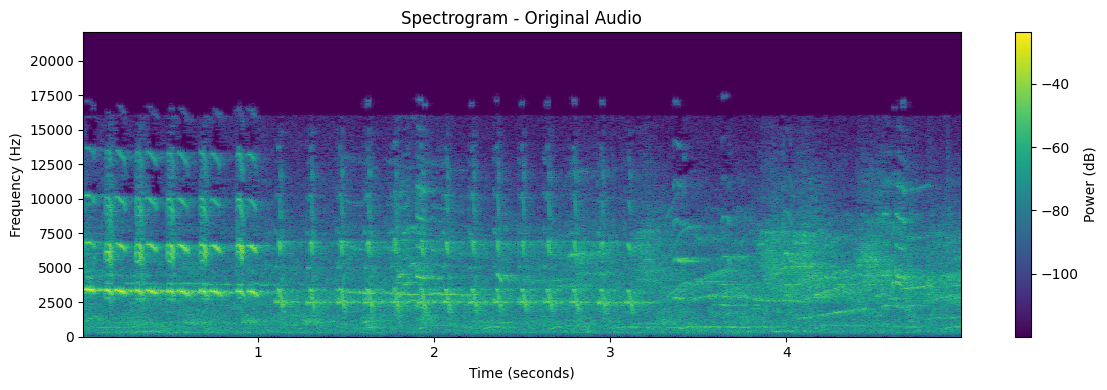

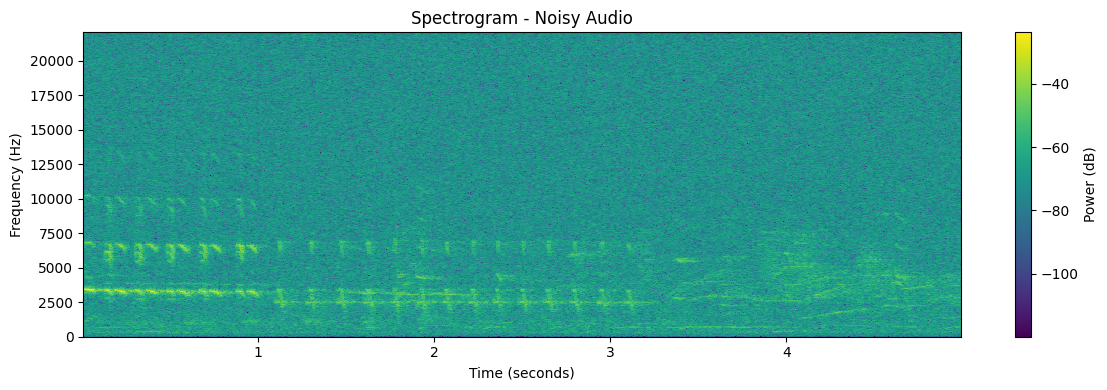

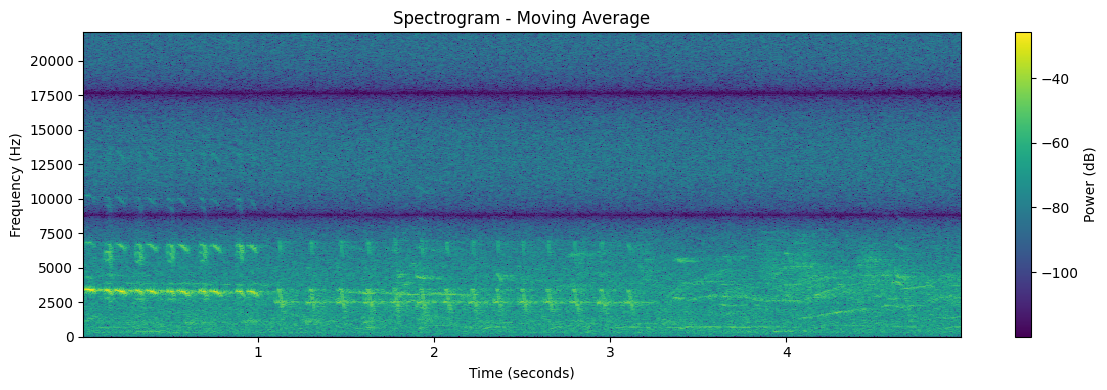

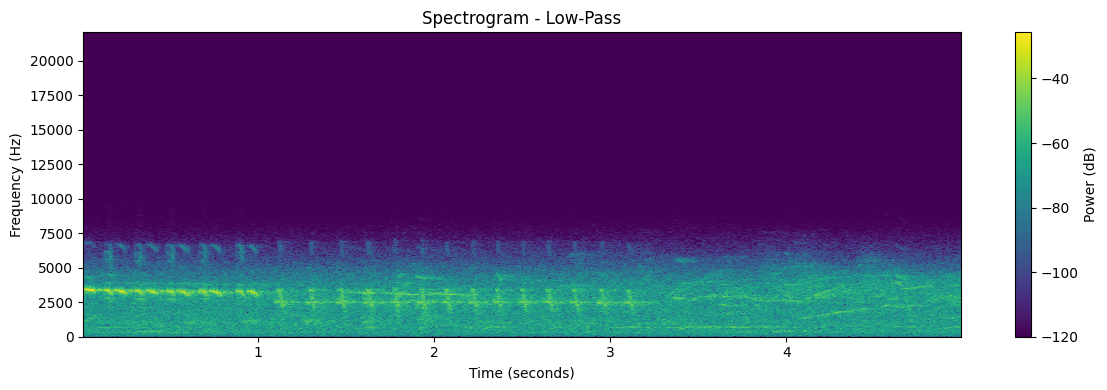

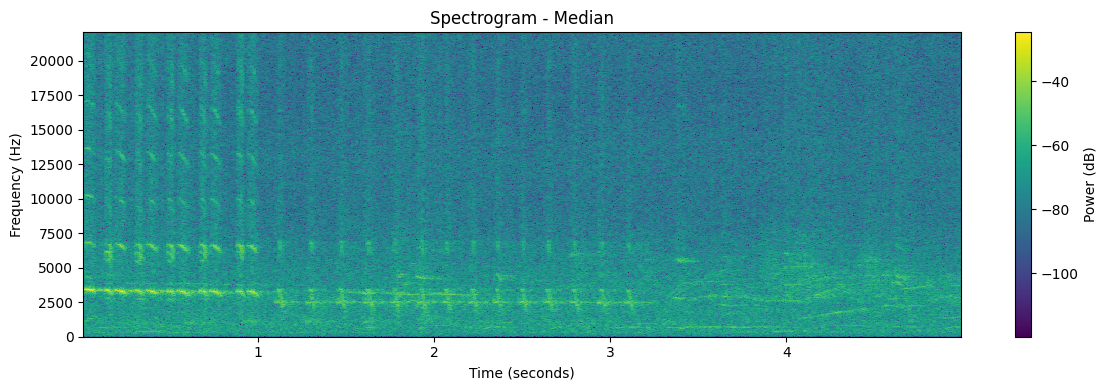

In [21]:
signals_to_compare = {
    "Original Audio": audio,
    "Noisy Audio": noisy_audio,
    "Moving Average": moving_avg_audio,
    "Low-Pass": low_pass_audio,
    "Median": median_audio
}

for name, signal in signals_to_compare.items():
    frequencies, times, power = spectrogram(
        signal,
        fs=sr,
        nperseg=1024,
        noverlap=768
    )

    plt.figure(figsize=(12, 4))

    plt.pcolormesh(
        times,
        frequencies,
        10 * np.log10(power + 1e-12),
        shading="auto"
    )

    plt.title(f"Spectrogram - {name}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.colorbar(label="Power (dB)")
    plt.ylim(0, sr / 2)

    plt.tight_layout()
    plt.show()

In [22]:
filtered_results = {
    "Moving Average": moving_avg_audio,
    "Low-Pass": low_pass_audio,
    "Median": median_audio
}

filtered_metrics = {
    name: calculate_metrics(audio, signal)
    for name, signal in filtered_results.items()
}

best_filter_name = max(
    filtered_metrics,
    key=lambda name: filtered_metrics[name][2]
)

best_audio = filtered_results[best_filter_name]

best_mse, best_rmse, best_snr = filtered_metrics[
    best_filter_name
]

print("Best filter according to output SNR:", best_filter_name)
print(f"MSE: {best_mse:.8f}")
print(f"RMSE: {best_rmse:.8f}")
print(f"SNR: {best_snr:.2f} dB")

Best filter according to output SNR: Median
MSE: 0.00170670
RMSE: 0.04131218
SNR: 8.71 dB


In [23]:
import soundfile as sf

output_path = "denoised_audio.wav"

# Keep samples within the standard audio range
audio_to_save = np.clip(best_audio, -1, 1)

sf.write(
    output_path,
    audio_to_save,
    sr
)

print("Denoised audio saved successfully!")
print("File path:", output_path)

Denoised audio saved successfully!
File path: denoised_audio.wav


In [24]:
from pathlib import Path

print(Path(output_path).resolve())

C:\Users\hp\OneDrive - Faculty Of Engineering (Kafr Elsheikh University)\Desktop\Smart Audio Denoising System\denoised_audio.wav


In [25]:
report_path = "denoising_results.csv"

metrics_df.to_csv(report_path, index=True)

print("Results report saved successfully!")
print("File path:", Path(report_path).resolve())

Results report saved successfully!
File path: C:\Users\hp\OneDrive - Faculty Of Engineering (Kafr Elsheikh University)\Desktop\Smart Audio Denoising System\denoising_results.csv


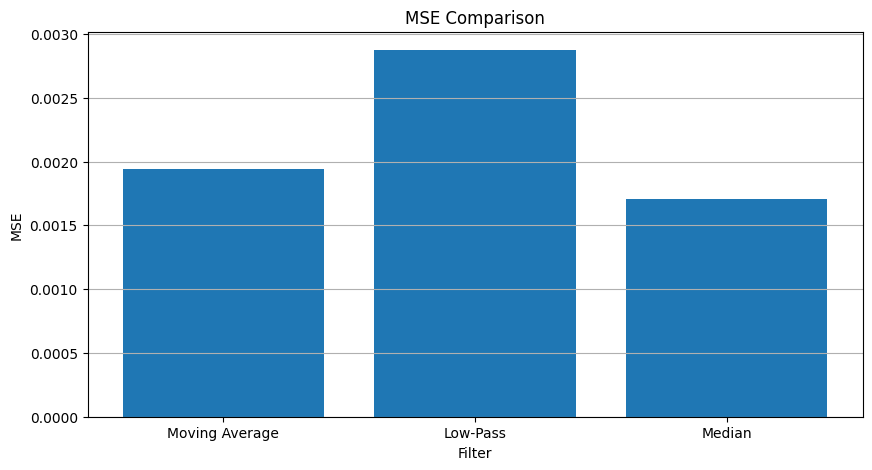

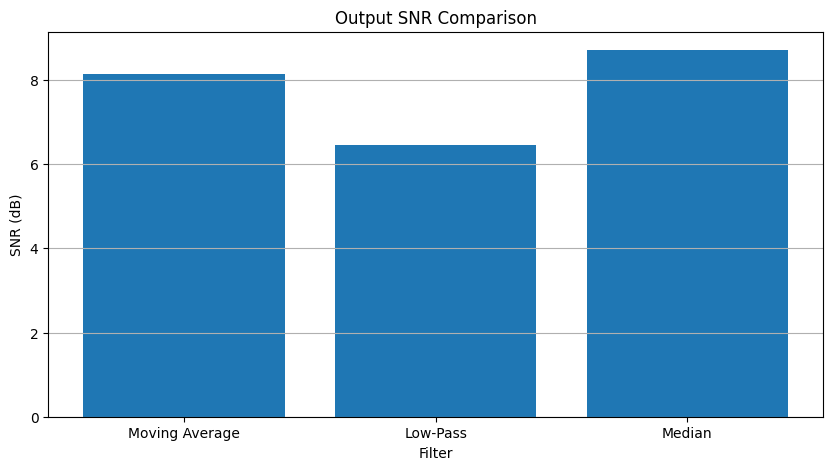

In [26]:
filter_names = list(filtered_metrics.keys())

mse_values = [
    filtered_metrics[name][0]
    for name in filter_names
]

snr_values = [
    filtered_metrics[name][2]
    for name in filter_names
]

plt.figure(figsize=(10, 5))

plt.bar(filter_names, mse_values)
plt.title("MSE Comparison")
plt.xlabel("Filter")
plt.ylabel("MSE")
plt.grid(axis="y")

plt.show()


plt.figure(figsize=(10, 5))

plt.bar(filter_names, snr_values)
plt.title("Output SNR Comparison")
plt.xlabel("Filter")
plt.ylabel("SNR (dB)")
plt.grid(axis="y")

plt.show()

In [27]:
noise_levels = [0.01, 0.03, 0.05, 0.10]

noise_experiment_results = []

for level in noise_levels:
    rng = np.random.default_rng(42)

    test_noise = rng.normal(
        loc=0,
        scale=level,
        size=len(audio)
    )

    test_noisy_audio = audio + test_noise

    filtered_test_audio = low_pass_filter(
        test_noisy_audio,
        sampling_rate=sr,
        cutoff=4000
    )

    noisy_mse, noisy_rmse, noisy_snr = calculate_metrics(
        audio,
        test_noisy_audio
    )

    filtered_mse, filtered_rmse, filtered_snr = calculate_metrics(
        audio,
        filtered_test_audio
    )

    noise_experiment_results.append({
        "Noise Level": level,
        "Noisy MSE": noisy_mse,
        "Filtered MSE": filtered_mse,
        "Noisy SNR (dB)": noisy_snr,
        "Filtered SNR (dB)": filtered_snr
    })

noise_experiment_df = pd.DataFrame(
    noise_experiment_results
)

display(noise_experiment_df.round(6))

,Noise Level,Noisy MSE,Filtered MSE,Noisy SNR (dB),Filtered SNR (dB)
0,0.01,0.000100,0.002477,21.014957,7.091768
1,0.03,0.000903,0.002608,11.472532,6.867994
2,0.05,0.002509,0.002871,7.035557,6.451288
3,0.10,0.010038,0.004103,1.014957,4.899804


In [28]:
import ipywidgets as widgets
from IPython.display import display, Audio, clear_output

filter_selector = widgets.Dropdown(
    options=[
        "Moving Average",
        "Low-Pass",
        "Median"
    ],
    value="Low-Pass",
    description="Filter:"
)

play_button = widgets.Button(
    description="Play Result",
    button_style="success"
)

output = widgets.Output()


def play_selected_filter(button):
    with output:
        clear_output(wait=True)

        selected_filter = filter_selector.value

        if selected_filter == "Moving Average":
            selected_audio = moving_avg_audio

        elif selected_filter == "Low-Pass":
            selected_audio = low_pass_audio

        else:
            selected_audio = median_audio

        print("Selected filter:", selected_filter)

        display(
            Audio(
                selected_audio,
                rate=sr
            )
        )


play_button.on_click(play_selected_filter)

display(filter_selector, play_button, output)

Dropdown(description='Filter:', index=1, options=('Moving Average', 'Low-Pass', 'Median'), value='Low-Pass')

Button(button_style='success', description='Play Result', style=ButtonStyle())

Output()

In [29]:
print("=" * 50)
print("SMART AUDIO DENOISING SYSTEM")
print("=" * 50)

print(f"Sampling Rate: {sr} Hz")
print(f"Audio Duration: {len(audio) / sr:.2f} seconds")
print(f"Original Samples: {len(audio)}")
print(f"Noise Level Used Initially: {noise_level}")

print("\nFilter Performance:")

for name, (mse, rmse, snr) in filtered_metrics.items():
    print(f"\n{name}")
    print(f"  MSE: {mse:.8f}")
    print(f"  RMSE: {rmse:.8f}")
    print(f"  SNR: {snr:.2f} dB")

print("\nBest Filter by Output SNR:", best_filter_name)
print("Saved Audio:", output_path)
print("Saved Report:", report_path)

print("\nProject experiment completed!")

SMART AUDIO DENOISING SYSTEM
Sampling Rate: 44100 Hz
Audio Duration: 5.00 seconds
Original Samples: 220500
Noise Level Used Initially: 0.05

Filter Performance:

Moving Average
  MSE: 0.00194215
  RMSE: 0.04406986
  SNR: 8.15 dB

Low-Pass
  MSE: 0.00287341
  RMSE: 0.05360416
  SNR: 6.45 dB

Median
  MSE: 0.00170670
  RMSE: 0.04131218
  SNR: 8.71 dB

Best Filter by Output SNR: Median
Saved Audio: denoised_audio.wav
Saved Report: denoising_results.csv

Project experiment completed!
